In [14]:
from pathlib import Path

import pandas as pd
import numpy as np

DATA_PATH = Path("../data/ml/ml_ready_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes.value_counts())

Dataset shape: (62605, 25)


,host_identity_verified,lat,long,instant_bookable,price,service fee,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365,Property Age,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island,room type_Entire home/apt,room type_Hotel room,room type_Private room,room type_Shared room,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict
0,0,40.64749,-73.97237,0,966,193,10,9.0,0.21,4,6,286,6,0,1,0,0,0,0,0,1,0,0,0,1
1,1,40.75362,-73.98377,0,142,28,30,45.0,0.38,4,2,228,19,0,0,1,0,0,1,0,0,0,0,1,0
2,0,40.80902,-73.94190,1,620,124,3,0.0,0.74,5,1,352,21,0,0,1,0,0,0,0,1,0,1,0,0
3,0,40.68514,-73.95976,1,368,74,30,270.0,4.64,4,1,322,21,0,1,0,0,0,1,0,0,0,0,1,0
4,1,40.79851,-73.94399,0,204,41,10,9.0,0.10,3,1,289,17,0,0,1,0,0,1,0,0,0,0,1,0



Missing values: 0
Duplicate rows: 0

Data types:
int64      21
float64     4
Name: count, dtype: int64



# Airbnb Listing Clustering

## Objective
Explore unsupervised machine learning to group Airbnb listings into meaningful segments based on their property characteristics, pricing, reviews, and availability.

## Approach
1. Validate the ML-ready dataset and inspect feature distributions.
2. Select relevant features and handle scale differences.
3. Establish a K-Means baseline and evaluate candidate cluster counts.
4. Profile and interpret the resulting clusters.
5. Compare alternative methods if the baseline results justify it.

## Important Note
This notebook is exploratory. Clustering results will be evaluated using quantitative metrics and business interpretability before selecting a final model.


In [15]:

# Inspect features and their distributions
pd.set_option("display.max_columns", None)

display(df.head())
display(df.describe().T)

print("Columns:")
print(df.columns.tolist())


,host_identity_verified,lat,long,instant_bookable,price,service fee,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365,Property Age,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island,room type_Entire home/apt,room type_Hotel room,room type_Private room,room type_Shared room,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict
0,0,40.64749,-73.97237,0,966,193,10,9.0,0.21,4,6,286,6,0,1,0,0,0,0,0,1,0,0,0,1
1,1,40.75362,-73.98377,0,142,28,30,45.0,0.38,4,2,228,19,0,0,1,0,0,1,0,0,0,0,1,0
2,0,40.80902,-73.94190,1,620,124,3,0.0,0.74,5,1,352,21,0,0,1,0,0,0,0,1,0,1,0,0
3,0,40.68514,-73.95976,1,368,74,30,270.0,4.64,4,1,322,21,0,1,0,0,0,1,0,0,0,0,1,0
4,1,40.79851,-73.94399,0,204,41,10,9.0,0.10,3,1,289,17,0,0,1,0,0,1,0,0,0,0,1,0


,count,mean,std,min,25%,50%,75%,max
host_identity_verified,62605.0,0.498347,0.500001,0.00000,0.00000,0.00000,1.00000,1.00000
lat,62605.0,40.727970,0.056084,40.49979,40.68855,40.72249,40.76269,40.91697
long,62605.0,-73.948905,0.050772,-74.24984,-73.98288,-73.95439,-73.93108,-73.70522
instant_bookable,62605.0,0.495583,0.499984,0.00000,0.00000,0.00000,1.00000,1.00000
price,62605.0,524.217443,273.971524,50.00000,286.00000,525.00000,760.00000,999.00000
service fee,62605.0,124.924431,66.282264,10.00000,68.00000,125.00000,182.00000,240.00000
minimum nights,62605.0,8.133056,35.042413,1.00000,1.00000,3.00000,5.00000,5645.00000
number of reviews,62605.0,27.364060,51.651722,0.00000,1.00000,7.00000,28.00000,1024.00000
reviews per month,62605.0,1.343754,1.704871,0.01000,0.33000,0.74000,1.83000,90.00000
review rate number,62605.0,3.325757,1.253304,1.00000,2.00000,3.00000,4.00000,5.00000


Columns:
['host_identity_verified', 'lat', 'long', 'instant_bookable', 'price', 'service fee', 'minimum nights', 'number of reviews', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'Property Age', 'neighbourhood group_Bronx', 'neighbourhood group_Brooklyn', 'neighbourhood group_Manhattan', 'neighbourhood group_Queens', 'neighbourhood group_Staten Island', 'room type_Entire home/apt', 'room type_Hotel room', 'room type_Private room', 'room type_Shared room', 'cancellation_policy_flexible', 'cancellation_policy_moderate', 'cancellation_policy_strict']


In [16]:

# Check numeric ranges and potential invalid values
numeric_df = df.select_dtypes(include=np.number)

quality_summary = pd.DataFrame({
    "min": numeric_df.min(),
    "max": numeric_df.max(),
    "unique_values": numeric_df.nunique(),
    "std": numeric_df.std()
})

display(quality_summary.sort_values("std", ascending=False))

# Check known Airbnb constraints where applicable
for col in ["minimum nights", "availability 365", "price", "service fee"]:
    if col in df.columns:
        print(f"\n{col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Negative values:", (df[col] < 0).sum())


,min,max,unique_values,std
price,50.00000,999.00000,949,273.971524
availability 365,0.00000,365.00000,366,127.975598
service fee,10.00000,240.00000,231,66.282264
number of reviews,0.00000,1024.00000,472,51.651722
calculated host listings count,1.00000,332.00000,78,35.215532
minimum nights,1.00000,5645.00000,128,35.042413
Property Age,4.00000,23.00000,20,5.751659
reviews per month,0.01000,90.00000,1016,1.704871
review rate number,1.00000,5.00000,5,1.253304
host_identity_verified,0.00000,1.00000,2,0.500001



minimum nights
Minimum: 1
Maximum: 5645
Negative values: 0

availability 365
Minimum: 0
Maximum: 365
Negative values: 0

price
Minimum: 50
Maximum: 999
Negative values: 0

service fee
Minimum: 10
Maximum: 240
Negative values: 0


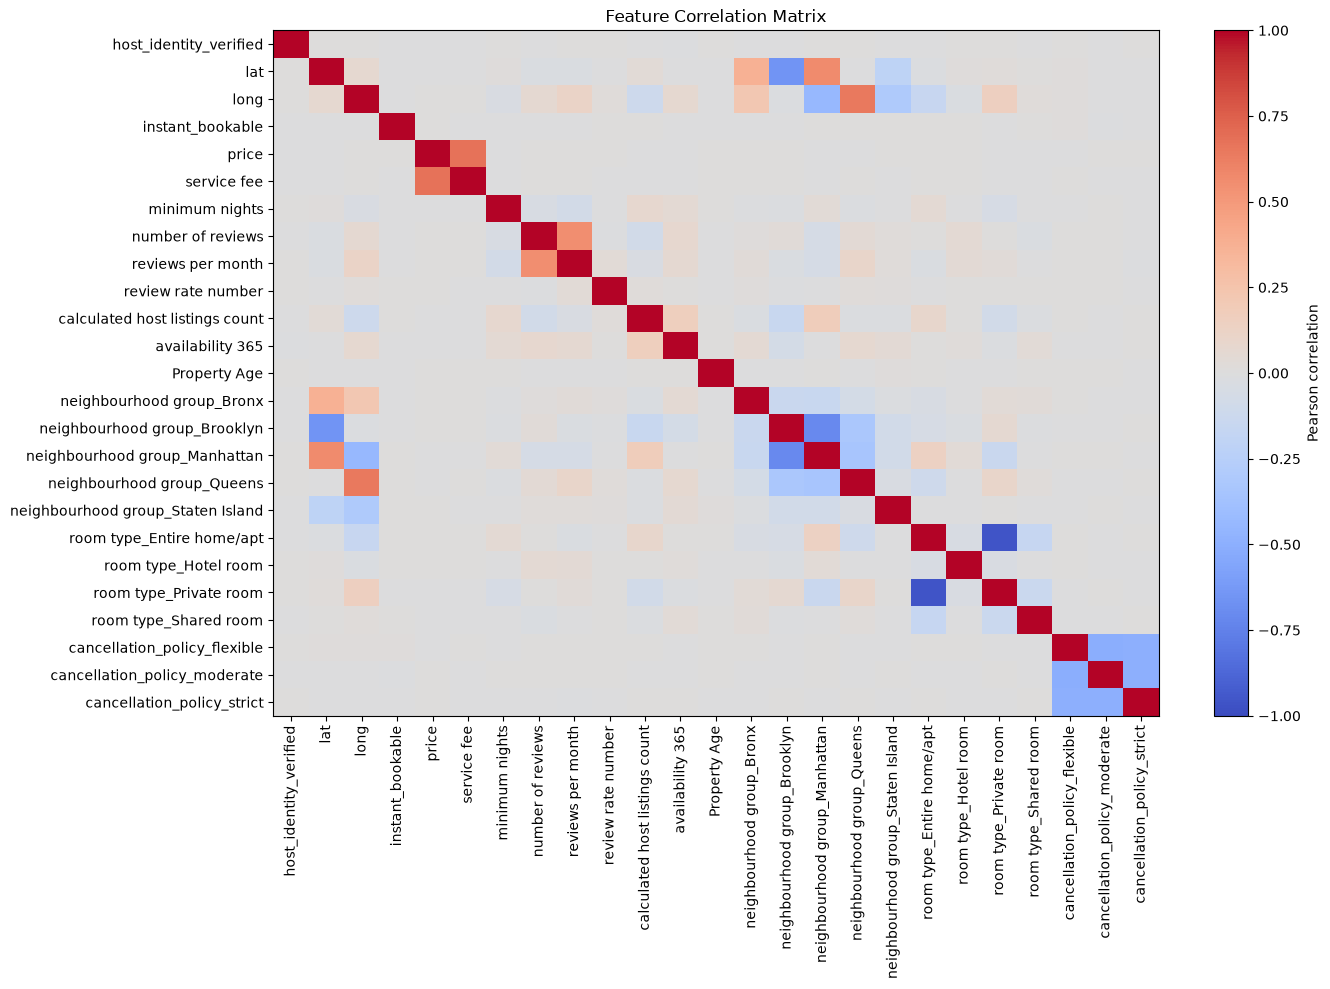

In [17]:

import matplotlib.pyplot as plt

corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [18]:

# Create a separate clustering dataset
df_cluster = df.copy()

# Cap extreme minimum-night values at 365 days
df_cluster["minimum nights"] = df_cluster["minimum nights"].clip(upper=365)

print("Maximum after capping:", df_cluster["minimum nights"].max())
print(
    "Values above 365:",
    (df_cluster["minimum nights"] > 365).sum()
)


Maximum after capping: 365
Values above 365: 0


In [19]:

# Apply log1p to skewed numerical features.
# minimum nights has already been capped at 365 in the preceding cell.
# The transformation reduces the influence of very large values.

features_to_transform = [
    "minimum nights",
    "number of reviews",
    "calculated host listings count"
]

for col in features_to_transform:
    df_cluster[col] = np.log1p(df_cluster[col])

# Exclude service fee to avoid double-weighting correlated pricing information.
excluded_features = ["service fee"]
X = df_cluster.drop(columns=excluded_features)

# Verify the transformed feature ranges.
print("Feature matrix shape:", X.shape)
display(X[features_to_transform].describe().T)


Feature matrix shape: (62605, 24)


,count,mean,std,min,25%,50%,75%,max
minimum nights,62605.0,1.571464,0.936014,0.693147,0.693147,1.386294,1.791759,5.902633
number of reviews,62605.0,2.167013,1.569898,0.000000,0.693147,2.079442,3.367296,6.932448
calculated host listings count,62605.0,1.202376,0.977199,0.693147,0.693147,0.693147,1.386294,5.808142


In [20]:

from sklearn.preprocessing import RobustScaler

# Identify binary / one-hot columns
binary_cols = [
    col for col in X.columns
    if X[col].nunique() <= 2
    and set(X[col].dropna().unique()).issubset({0, 1})
]

continuous_cols = [
    col for col in X.columns
    if col not in binary_cols
]

X_scaled = X.copy()

scaler = RobustScaler()
X_scaled[continuous_cols] = scaler.fit_transform(
    X[continuous_cols]
)

print("Continuous features scaled:", len(continuous_cols))
print("Binary / one-hot features preserved:", len(binary_cols))
print("Scaled matrix shape:", X_scaled.shape)

display(X_scaled.head())


Continuous features scaled: 10
Binary / one-hot features preserved: 14
Scaled matrix shape: (62605, 24)


,host_identity_verified,lat,long,instant_bookable,price,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365,Property Age,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island,room type_Entire home/apt,room type_Hotel room,room type_Private room,room type_Shared room,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict
0,0,-1.011600,-0.347104,0,0.930380,0.920799,0.083445,-0.353333,0.5,1.807355,0.661290,-0.888889,0,1,0,0,0,0,0,1,0,0,0,1
1,1,0.419881,-0.567181,0,-0.808017,1.863890,0.654115,-0.240000,0.5,0.584963,0.427419,0.555556,0,0,1,0,0,1,0,0,0,0,1,0
2,0,1.167116,0.241120,1,0.200422,0.000000,-0.777609,0.000000,1.0,0.000000,0.927419,0.777778,0,0,1,0,0,0,0,1,0,1,0,0
3,0,-0.503777,-0.103668,1,-0.331224,1.863890,1.317308,2.600000,0.5,0.000000,0.806452,0.777778,0,1,0,0,0,1,0,0,0,0,1,0
4,1,1.025357,0.200772,0,-0.677215,0.920799,0.083445,-0.426667,0.0,0.000000,0.673387,0.333333,0,0,1,0,0,1,0,0,0,0,1,0


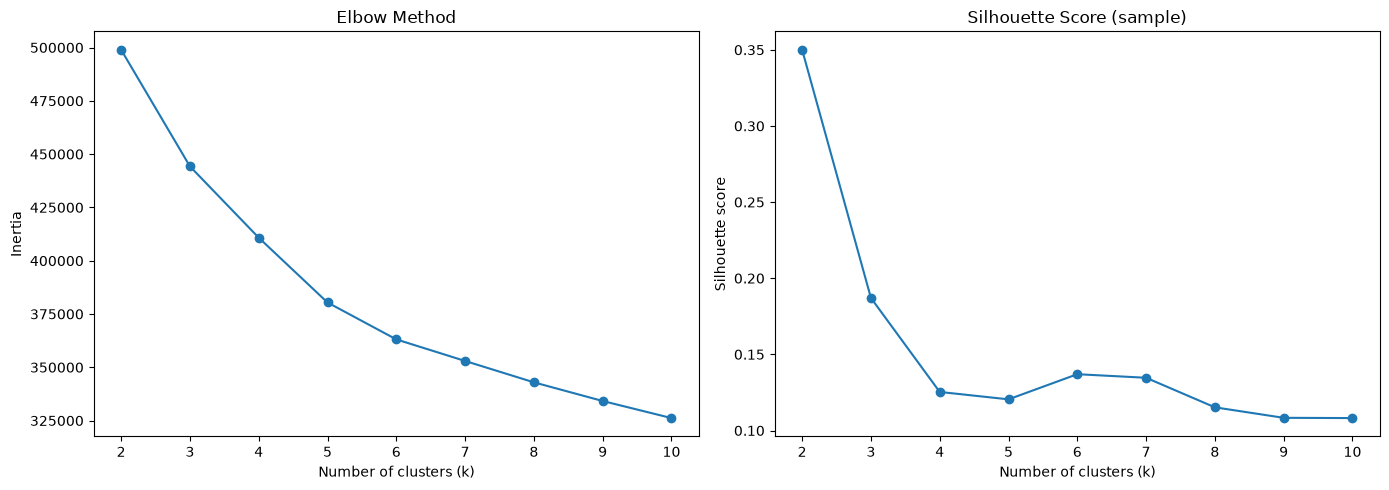

,k,inertia,silhouette_score
0,2,498951.674483,0.350047
1,3,444255.132383,0.187059
2,4,410791.854845,0.125325
3,5,380396.415842,0.120463
4,6,363082.819153,0.136975
5,7,352966.609585,0.134627
6,8,342943.407333,0.115224
7,9,334188.167178,0.108332
8,10,326177.126548,0.108159


In [21]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 11)
inertias = []
silhouette_scores = []

# Use a reproducible sample for silhouette calculations
sample_size = min(5000, len(X_scaled))
sample_idx = X_scaled.sample(
    n=sample_size, random_state=42
).index

X_sample = X_scaled.loc[sample_idx]

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    
    sample_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    sample_labels = sample_model.fit_predict(X_sample)
    
    silhouette_scores.append(
        silhouette_score(X_sample, sample_labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score (sample)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
}))



## Initial K-Means Experiment: Data Preparation and Evaluation

### 1. Feature Preparation
- **Outlier treatment:** Capped `minimum nights` at 365 to reduce the influence of extreme values while retaining all listings.
- **Feature transformation:** Applied `log1p` to `number of reviews` and `calculated host listings count` to reduce right-skewness.
- **Feature selection:** Excluded `service fee` because it is strongly correlated with `price`, potentially overemphasizing pricing in distance calculations.
- **Feature scaling:** Applied `RobustScaler` to continuous features while retaining binary and one-hot encoded variables in their original 0/1 form.

### 2. Evaluation Methodology
K-Means was evaluated for cluster counts ranging from **k = 2 to k = 10**.

Two metrics were used:
- **Inertia (Elbow Method):** Measures the total squared distance between observations and their assigned cluster centers. Lower inertia indicates tighter clusters, but it naturally decreases as the number of clusters increases.
- **Silhouette Score:** Measures how well observations fit within their assigned clusters compared with neighbouring clusters. Scores closer to 1 indicate stronger separation, scores near 0 suggest overlap, and negative scores may indicate poor assignments.

Inertia was calculated using the full dataset. Silhouette scores were estimated using a reproducible sample of 5,000 listings.

### 3. Results and Interpretation
- **Elbow method:** Inertia decreases sharply from k = 2 to k = 3, decreases further at k = 4, and then declines more gradually. This suggests investigating k = 3 and k = 4 as potential compromises between compactness and model complexity.
- **Silhouette score:** The highest score occurs at k = 2 (approximately 0.934). Scores decrease to approximately 0.526 at k = 3 and 0.508 at k = 4, then fall substantially for k ≥ 5.
- **Initial interpretation:** The two-cluster solution has unusually strong separation under the current feature representation. However, it may reflect a broad structural split rather than sufficiently detailed business segments. The scores for k = 3 and k = 4 indicate weaker separation but may offer more useful segmentation detail.

### 4. Limitations
- The selected upper bound of 365 for `minimum nights` is a project-level assumption and should be documented.
- Silhouette scores are sample-based estimates and may vary with the sample and feature representation.
- Scaling does not eliminate outliers or ensure that every feature contributes equally to Euclidean distance.
- Numerical metrics alone cannot establish whether clusters are useful or interpretable for business decisions.

### 5. Next Steps
1. Fit K-Means models for k = 2, 3, and 4 using the same prepared feature matrix.
2. Compare cluster sizes and inspect the original-unit feature profiles of each segment.
3. Check whether clusters are dominated by location, room type, pricing, or other individual features.
4. Assess cluster stability and business interpretability before selecting the final number of clusters.

**Current status:** The initial experiment provides candidate cluster counts, not a finalized segmentation model. The next stage is cluster profiling and validation.


In [22]:

from sklearn.cluster import KMeans
import pandas as pd

candidate_models = {}
cluster_labels = {}
cluster_sizes = []

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    candidate_models[k] = model
    cluster_labels[k] = labels

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in counts.items():
        cluster_sizes.append({
            "k": k,
            "cluster": cluster_id,
            "listings": count,
            "percentage": round(count / len(X_scaled) * 100, 2)
        })

display(pd.DataFrame(cluster_sizes))


,k,cluster,listings,percentage
0,2,0,5307,8.48
1,2,1,57298,91.52
2,3,0,5086,8.12
3,3,1,41513,66.31
4,3,2,16006,25.57
5,4,0,26077,41.65
6,4,1,4746,7.58
7,4,2,21482,34.31
8,4,3,10300,16.45


In [23]:

# Build an interpretation dataset in original units
df_profile = df.copy()

if "minimum nights" in df_profile.columns:
    df_profile["minimum nights"] = (
        df_profile["minimum nights"].clip(upper=365)
    )

# Identify one-hot encoded categorical features
category_groups = {
    "Neighbourhood": [
        c for c in df_profile.columns
        if c.startswith("neighbourhood group_")
    ],
    "Room type": [
        c for c in df_profile.columns
        if c.startswith("room type_")
    ],
    "Cancellation policy": [
        c for c in df_profile.columns
        if c.startswith("cancellation_policy_")
    ]
}

profile_tables = {}

for k, labels in cluster_labels.items():
    temp = df_profile.copy()
    temp["cluster"] = labels

    # Mean values: numeric averages and proportions for 0/1 columns
    profile = temp.groupby("cluster").mean(numeric_only=True).round(2)
    profile_tables[k] = profile

    print(f"\nCluster profiles for k={k}")
    display(profile)

    for group_name, columns in category_groups.items():
        if columns:
            print(f"{group_name} distribution (%)")
            display((profile[columns] * 100).round(1))



Cluster profiles for k=2


,host_identity_verified,lat,long,instant_bookable,price,service fee,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365,Property Age,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island,room type_Entire home/apt,room type_Hotel room,room type_Private room,room type_Shared room,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict
cluster,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.49,40.74,-73.97,0.5,518.01,123.81,22.68,6.93,0.80,3.43,86.34,240.84,13.58,0.01,0.13,0.78,0.09,0.00,0.64,0.0,0.34,0.02,0.34,0.34,0.32
1,0.50,40.73,-73.95,0.5,524.79,125.03,6.51,29.26,1.39,3.32,1.88,139.37,13.50,0.03,0.43,0.39,0.14,0.01,0.53,0.0,0.45,0.02,0.33,0.33,0.33


Neighbourhood distribution (%)


,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island
cluster,,,,,
0,1.0,13.0,78.0,9.0,0.0
1,3.0,43.0,39.0,14.0,1.0


Room type distribution (%)


...

,neighbourhood group_Bronx,neighbourhood group_Brooklyn,neighbourhood group_Manhattan,neighbourhood group_Queens,neighbourhood group_Staten Island
cluster,,,,,
0,1.0,79.0,0.0,20.0,1.0
1,0.0,11.0,79.0,9.0,0.0
2,5.0,0.0,93.0,1.0,2.0
3,6.0,39.0,29.0,25.0,1.0


Room type distribution (%)


,room type_Entire home/apt,room type_Hotel room,room type_Private room,room type_Shared room
cluster,,,,
0,48.0,0.0,50.0,2.0
1,67.0,0.0,32.0,1.0
2,60.0,0.0,38.0,2.0
3,49.0,0.0,48.0,2.0


Cancellation policy distribution (%)


,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict
cluster,,,
0,33.0,33.0,34.0
1,34.0,33.0,33.0
2,34.0,33.0,33.0
3,34.0,34.0,32.0


In [24]:

from sklearn.metrics import silhouette_samples, silhouette_score

sample_idx = X_scaled.sample(
    n=min(5000, len(X_scaled)),
    random_state=42
).index

silhouette_results = []

for k, labels in cluster_labels.items():
    labels_series = pd.Series(labels, index=X_scaled.index)

    X_sample = X_scaled.loc[sample_idx]
    labels_sample = labels_series.loc[sample_idx]

    sample_scores = silhouette_samples(
        X_sample, labels_sample
    )

    print(f"\nk={k}: overall sample silhouette = "
          f"{silhouette_score(X_sample, labels_sample):.3f}")

    score_df = pd.DataFrame({
        "cluster": labels_sample.to_numpy(),
        "silhouette": sample_scores
    })

    display(
        score_df.groupby("cluster")["silhouette"]
        .agg(["mean", "median", "min", "max", "count"])
        .round(3)
    )

    for cluster_id, group in score_df.groupby("cluster"):
        silhouette_results.append({
            "k": k,
            "cluster": cluster_id,
            "mean_silhouette": group["silhouette"].mean(),
            "negative_score_pct": (
                group["silhouette"].lt(0).mean() * 100
            )
        })

display(pd.DataFrame(silhouette_results).round(2))



k=2: overall sample silhouette = 0.350


,mean,median,min,max,count
cluster,,,,,
0,0.325,0.377,0.005,0.507,415
1,0.352,0.381,-0.014,0.464,4585



k=3: overall sample silhouette = 0.181


,mean,median,min,max,count
cluster,,,,,
0,0.321,0.369,-0.026,0.509,399
1,0.216,0.226,0.021,0.332,3353
2,0.041,0.031,-0.102,0.234,1248



k=4: overall sample silhouette = 0.124


,mean,median,min,max,count
cluster,,,,,
0,0.100,0.102,-0.024,0.203,2069
1,0.336,0.394,-0.039,0.518,370
2,0.138,0.144,0.013,0.216,1733
3,0.063,0.050,-0.099,0.275,828


,k,cluster,mean_silhouette,negative_score_pct
0,2,0,0.33,0.00
1,2,1,0.35,0.07
2,3,0,0.32,3.76
3,3,1,0.22,0.00
4,3,2,0.04,36.86
5,4,0,0.10,2.32
6,4,1,0.34,3.24
7,4,2,0.14,0.00
8,4,3,0.06,33.33


Variance explained by first two components: 38.35 %


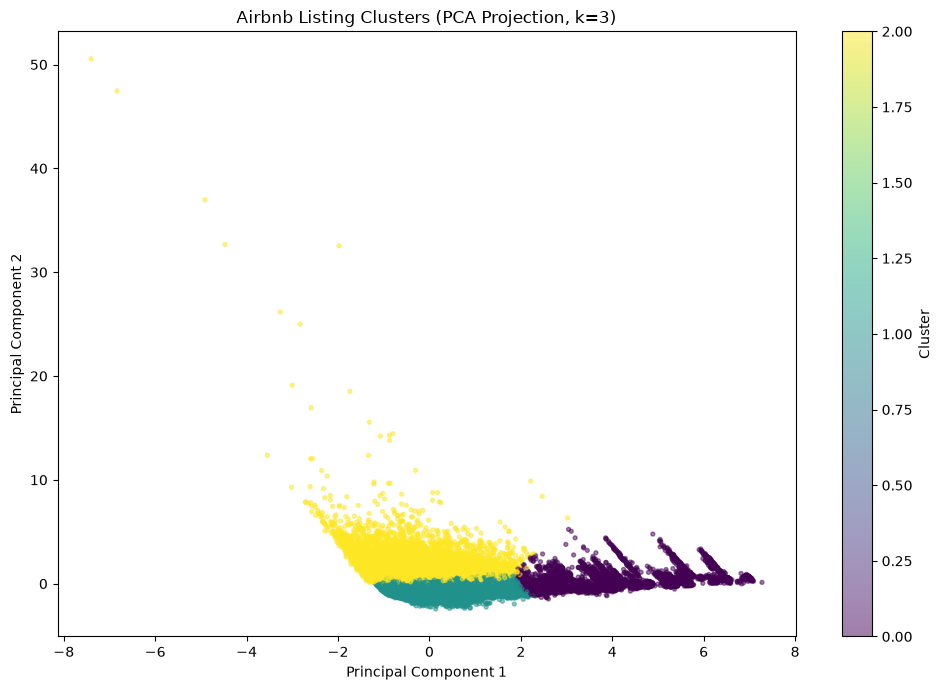

In [25]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Plot k=3 as an initial visualization
k = 3
labels = cluster_labels[k]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    s=8,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Airbnb Listing Clusters (PCA Projection, k=3)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()



## Cluster Profiling and Validation

### Objective
The initial K-Means experiment identified k = 2, 3, and 4 as candidate cluster counts. This stage investigates whether these clusters are well-separated, sufficiently balanced, and interpretable as meaningful Airbnb listing segments.

### 1. Candidate Model Fitting — Cell 9
Fit K-Means models for k = 2, 3, and 4 using the prepared, scaled feature matrix. Record the number and percentage of listings assigned to each cluster.

**Purpose:** Identify highly imbalanced clusters and compare how segmentation changes as the number of clusters increases.

### 2. Cluster Profiling — Cell 10
Summarize listing characteristics within each cluster using the original feature units. Examine pricing, minimum nights, reviews, host listing counts, neighbourhoods, room types, and cancellation policies.

**Purpose:** Understand what distinguishes each cluster and develop interpretable segment descriptions. For one-hot encoded categorical variables, cluster means represent the proportion of listings belonging to each category.

### 3. Silhouette Analysis — Cell 11
Calculate silhouette scores for individual listings in a reproducible sample and summarize the results by cluster.

**Purpose:** Determine whether the overall separation score hides poorly separated clusters or listings that may fit better in another cluster. Negative silhouette scores indicate potentially questionable assignments.

### 4. PCA Visualization — Cell 12
Apply Principal Component Analysis (PCA) to project the scaled feature matrix into two dimensions and visualize the k = 3 solution.

**Purpose:** Explore the spatial structure of the clusters visually. The percentage of variance explained by the two components indicates how much of the original feature variation is represented in the plot.

### Interpretation Guidelines
- **Cluster size:** Very small clusters may represent niche groups or outlier-driven segments.
- **Feature profiles:** Differences in pricing, room type, location, and listing characteristics help establish business meaning.
- **Silhouette scores:** Higher scores indicate better separation, but should be interpreted alongside cluster-level results.
- **PCA plot:** Visible separation can support interpretation, but overlap in two dimensions does not necessarily mean clusters overlap in the full feature space.
- **Model selection:** No single metric determines the final number of clusters. Consider separation, balance, stability, and business interpretability together.

### Important Considerations
- The same prepared feature matrix and random seed are used to make candidate comparisons reproducible.
- PCA is used for visualization, not as a replacement for the original clustering features.
- These experiments remain exploratory; the final segmentation has not yet been selected.

### Next Step
Compare the profiles and validation results for k = 2, 3, and 4. Select a candidate only after understanding what drives its segments and checking whether the results are sufficiently stable and useful for Airbnb listing analysis.


In [26]:

# Inspect the capped minimum-night distribution.
# Large gaps between the median and upper percentiles can indicate skewness.
display(
    df_cluster["minimum nights"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .rename("minimum_nights")
    .to_frame()
)

# Inspect the features contributing most strongly to the first two PCA axes.
# Absolute loadings indicate contribution strength; the sign indicates direction.
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=X_scaled.columns,
    columns=["PC1", "PC2"]
)

pca_loadings["abs_PC1"] = pca_loadings["PC1"].abs()
pca_loadings["abs_PC2"] = pca_loadings["PC2"].abs()

print("Top contributors to PC1:")
display(pca_loadings.sort_values("abs_PC1", ascending=False).head(10))

print("Top contributors to PC2:")
display(pca_loadings.sort_values("abs_PC2", ascending=False).head(10))

# Identify constant columns that cannot help distinguish listings.
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features:", constant_features)


,minimum_nights
0.50,1.386294
0.75,1.791759
0.90,3.433987
0.95,3.433987
0.99,3.828641
1.00,5.902633


Top contributors to PC1:


,PC1,PC2,abs_PC1,abs_PC2
calculated host listings count,0.919944,0.273989,0.919944,0.273989
minimum nights,0.281885,-0.236699,0.281885,0.236699
reviews per month,-0.154216,0.837149,0.154216,0.837149
long,-0.122952,0.281683,0.122952,0.281683
availability 365,0.096972,0.071591,0.096972,0.071591
neighbourhood group_Manhattan,0.093578,-0.061223,0.093578,0.061223
number of reviews,-0.084473,0.257650,0.084473,0.257650
neighbourhood group_Brooklyn,-0.073730,-0.024248,0.073730,0.024248
lat,0.060572,-0.006336,0.060572,0.006336
room type_Private room,-0.016283,0.052189,0.016283,0.052189


Top contributors to PC2:


,PC1,PC2,abs_PC1,abs_PC2
reviews per month,-0.154216,0.837149,0.154216,0.837149
long,-0.122952,0.281683,0.122952,0.281683
calculated host listings count,0.919944,0.273989,0.919944,0.273989
number of reviews,-0.084473,0.257650,0.084473,0.257650
minimum nights,0.281885,-0.236699,0.281885,0.236699
neighbourhood group_Queens,-0.015938,0.077662,0.015938,0.077662
availability 365,0.096972,0.071591,0.096972,0.071591
neighbourhood group_Manhattan,0.093578,-0.061223,0.093578,0.061223
room type_Entire home/apt,0.012918,-0.055745,0.012918,0.055745
room type_Private room,-0.016283,0.052189,0.016283,0.052189


Constant features: []
